# E-Commerce A/B Testing & Conversion Rate Optimization

In [1]:
import pandas as pd
import numpy as np

df=pd.read_csv("ab_data.csv")
countries=pd.read_csv("countries.csv")

print("Experiment Dataset(df):")
print(df.head())

print("\nCountry Dataset(countries):")
print(countries.head())


Experiment Dataset(df):
   user_id                   timestamp      group landing_page  converted
0   851104  2017-01-21 22:11:48.556739    control     old_page          0
1   804228  2017-01-12 08:01:45.159739    control     old_page          0
2   661590  2017-01-11 16:55:06.154213  treatment     new_page          0
3   853541  2017-01-08 18:28:03.143765  treatment     new_page          0
4   864975  2017-01-21 01:52:26.210827    control     old_page          1

Country Dataset(countries):
   user_id country
0   834778      UK
1   928468      US
2   822059      UK
3   711597      UK
4   710616      UK


In [2]:
print(df.shape)
print(countries.shape)
df.columns
countries.columns

print(df.info())
print(countries.info())


(294478, 5)
(290584, 2)
<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       294478 non-null  int64
 1   timestamp     294478 non-null  str  
 2   group         294478 non-null  str  
 3   landing_page  294478 non-null  str  
 4   converted     294478 non-null  int64
dtypes: int64(2), str(3)
memory usage: 11.2 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 290584 entries, 0 to 290583
Data columns (total 2 columns):
 #   Column   Non-Null Count   Dtype
---  ------   --------------   -----
 0   user_id  290584 non-null  int64
 1   country  290584 non-null  str  
dtypes: int64(1), str(1)
memory usage: 4.4 MB
None


### Check missing values

In [3]:
print("Missing Values In df")
print(df.isnull().sum())
print("Missing Values In countries")
print(countries.isnull().sum())

Missing Values In df
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64
Missing Values In countries
user_id    0
country    0
dtype: int64


### Duplicate Check

In [4]:
print("Duplicate rows in df:")
print(df.duplicated().sum())

print("Duplicate rows in countries:")
print(countries.duplicated().sum())

Duplicate rows in df:
0
Duplicate rows in countries:
0


### Check duplicate user IDs

In [5]:
print("Unique User ID in df:",df['user_id'].nunique())
print("Duplicate User ID in df:",df['user_id'].duplicated().sum())

Unique User ID in df: 290584
Duplicate User ID in df: 3894


In [6]:
print("Unique users in countries:", countries['user_id'].nunique())
print("Duplicate User ID IN Countries:",countries['user_id'].duplicated().sum())

Unique users in countries: 290584
Duplicate User ID IN Countries: 0


### check categorical values

In [7]:
print("Group values:")
print(df['group'].value_counts())

print("\nLanding page values:")
print(df['landing_page'].value_counts())

print("\nConverted values:")
print(df['converted'].value_counts())

# From countries
print("\nCountry values:")
print(countries['country'].value_counts())

Group values:
group
treatment    147276
control      147202
Name: count, dtype: int64

Landing page values:
landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64

Converted values:
converted
0    259241
1     35237
Name: count, dtype: int64

Country values:
country
US    203619
UK     72466
CA     14499
Name: count, dtype: int64


### Compare group and landing page

In [8]:
pd.crosstab(df['group'], df['landing_page'])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


### Repeated User IDs

In [9]:
repeated_users=df[df['user_id'].duplicated()]['user_id'].unique()
print("Repeated user IDs:",repeated_users[:20])

df.loc[df['user_id'].isin(repeated_users[:5])]

Repeated user IDs: [698120 773192 899953 790934 633793 839784 926754 793494 892450 883654
 781656 790456 886965 870096 745943 700810 664347 779408 807355 667654]


,user_id,timestamp,group,landing_page,converted
988,698120,2017-01-22 07:09:37.540970,control,new_page,0
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2656,698120,2017-01-15 17:13:42.602796,control,old_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0
3489,899953,2017-01-05 05:36:02.120641,treatment,new_page,0
6755,790934,2017-01-09 07:19:43.446125,treatment,old_page,1
7500,899953,2017-01-07 03:06:54.068237,control,new_page,0
7691,633793,2017-01-17 20:45:03.581306,treatment,new_page,0
8036,790934,2017-01-19 08:32:20.329057,treatment,new_page,0
10218,633793,2017-01-17 00:16:00.746561,treatment,old_page,0


### Investigate Repeated Users

#### Count users appearing more than once

In [10]:
user_counts=df['user_id'].value_counts()

print("Users appearing more than once:",(user_counts>1).sum())
print("Users appearing exactly twice:",(user_counts==2).sum())
print("Maximum records for a single user:",user_counts.max())

Users appearing more than once: 3894
Users appearing exactly twice: 3894
Maximum records for a single user: 2


In [11]:
conflicts = df.groupby('user_id').agg({'group':'nunique',
'landing_page':'nunique','converted':'nunique'
})

conflicting_users = conflicts[(conflicts['group'] > 1) | 
                              (conflicts['landing_page'] > 1) | 
                              (conflicts['converted'] > 1)]

print("Number of users with conflicting assignments:",conflicting_users.shape[0])
print("\nSample of conflicting users:")
print(conflicting_users.head())


Number of users with conflicting assignments: 3893

Sample of conflicting users:
         group  landing_page  converted
user_id                                
630052       1             2          2
630126       1             2          1
630137       1             2          1
630320       2             1          1
630471       1             2          1


### investigate the conflicts

In [12]:
users_twice = user_counts[user_counts == 2].index

df_twice=df[df['user_id'].isin(users_twice)]
df_twice_sorted = df_twice.sort_values(by='user_id')


print(df_twice_sorted[['user_id','timestamp','group','landing_page','converted']].head(20))


        user_id                   timestamp      group landing_page  converted
213114   630052  2017-01-07 12:25:54.089486  treatment     old_page          1
230259   630052  2017-01-17 01:16:05.208766  treatment     new_page          0
251762   630126  2017-01-19 17:16:00.280440  treatment     new_page          0
22513    630126  2017-01-14 13:35:54.778695  treatment     old_page          0
11792    630137  2017-01-22 14:59:22.051308    control     new_page          0
183371   630137  2017-01-20 02:08:49.893878    control     old_page          0
255753   630320  2017-01-12 05:27:37.181803  treatment     old_page          0
207211   630320  2017-01-07 18:02:43.626318    control     old_page          0
110634   630471  2017-01-23 01:42:51.501851    control     old_page          0
96929    630471  2017-01-07 02:14:17.405726    control     new_page          0
201303   630780  2017-01-18 21:27:53.859949    control     new_page          0
1282     630780  2017-01-09 10:14:27.657854    contr

### Users with different experiment groups

In [13]:
users_diff_group = (conflicts['group']>1).sum()
print("Users with different experiment groups:",users_diff_group)


Users with different experiment groups: 1895


### users with different landing pages

In [14]:
users_diff_page = (conflicts['landing_page'] > 1).sum()
print("Users with different landing pages:",users_diff_page)


Users with different landing pages: 1998


### users with different conversion outcomes

In [15]:
users_diff_conv = (conflicts['converted'] > 1).sum()
print("Users with different conversion outcomes:", users_diff_conv)


Users with different conversion outcomes: 864


### valid experiment records

In [16]:
valid_records = ((df['group'] == 'control') & (df['landing_page'] == 'old_page')) | \
                ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))

print("Valid records:", valid_records.sum())
print("Invalid records:", (~valid_records).sum())


Valid records: 290585
Invalid records: 3893


### create a new DataFrame called df_valid using existing valid_records 

In [17]:
df_valid=df[valid_records]


### Check values for df_valid

In [18]:
print("Total rows in df_valid:",df_valid.shape[0])
print("Unique users in df_valid:",df_valid['user_id'].nunique())
print("Repeated user IDs in df_valid:",df_valid['user_id'].duplicated().sum())

Total rows in df_valid: 290585
Unique users in df_valid: 290584
Repeated user IDs in df_valid: 1


### Identify repeated user IDs

In [19]:
repeated_ids_valid =df_valid[df_valid['user_id'].duplicated()]['user_id'].unique()
print("Repeated user IDs in df_valid:",repeated_ids_valid)

Repeated user IDs in df_valid: [773192]


# Step 9: Remove the Remaining Duplicate User

### 9.1 Inspect the repeated user's records

In [20]:
# Display both records for user 773192
df_valid[df_valid['user_id']==773192][['user_id','timestamp','group','landing_page','converted']]

,user_id,timestamp,group,landing_page,converted
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


### 9.2 Remove one repeated record

##### keep the first record for each user_id and remove subsequent occurrences. 
##### Store the result in a new DataFrame named df_clean

In [21]:
df_clean=df_valid.drop_duplicates(subset=['user_id'],keep='first')

### 9.3 Validate the cleaned dataset

In [22]:
print("Total rows in df_clean:", df_clean.shape[0])
print("Unique users in df_clean:", df_clean['user_id'].nunique())

print("Repeated user IDs in df_clean:", df_clean['user_id'].duplicated().sum())

print("Missing values in df_clean:", df_clean.isnull().sum().sum())


valid_check = ((df_clean['group'] == 'control') & (df_clean['landing_page'] == 'old_page')) | \
              ((df_clean['group'] == 'treatment') & (df_clean['landing_page'] == 'new_page'))
print("Invalid records remaining:", (~valid_check).sum())

Total rows in df_clean: 290584
Unique users in df_clean: 290584
Repeated user IDs in df_clean: 0
Missing values in df_clean: 0
Invalid records remaining: 0


# Step 10: Exploratory Data Analysis (EDA)

### 10.1 Understand the final dataset

In [23]:
print(df_clean.head())

   user_id                   timestamp      group landing_page  converted
0   851104  2017-01-21 22:11:48.556739    control     old_page          0
1   804228  2017-01-12 08:01:45.159739    control     old_page          0
2   661590  2017-01-11 16:55:06.154213  treatment     new_page          0
3   853541  2017-01-08 18:28:03.143765  treatment     new_page          0
4   864975  2017-01-21 01:52:26.210827    control     old_page          1


In [24]:
print(df_clean.info())
print("Shape of df_clean:", df_clean.shape)

<class 'pandas.DataFrame'>
Index: 290584 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       290584 non-null  int64
 1   timestamp     290584 non-null  str  
 2   group         290584 non-null  str  
 3   landing_page  290584 non-null  str  
 4   converted     290584 non-null  int64
dtypes: int64(2), str(3)
memory usage: 13.3 MB
None
Shape of df_clean: (290584, 5)


### 10.2 Analyze the experiment groups

In [25]:
print("Group counts:")
print(df_clean['group'].value_counts())

Group counts:
group
treatment    145310
control      145274
Name: count, dtype: int64


### 10.3 Calculate overall conversions

In [26]:
print("Conversion counts:")

print(df_clean['converted'].value_counts())
print("Overall conversion rate:",df_clean['converted'].mean())

Conversion counts:
converted
0    255831
1     34753
Name: count, dtype: int64
Overall conversion rate: 0.11959708724499628


### 10.4 Analyze conversion rates by group

In [27]:
conversion_rates=df_clean.groupby('group')['converted'].mean()
print("Conversion rates by group:")
print(conversion_rates)

Conversion rates by group:
group
control      0.120386
treatment    0.118808
Name: converted, dtype: float64


# Step 11: Calculate the Conversion Difference and Relative Lift

###  11.1 Calculate the absolute conversion difference

In [28]:
abs_diff=conversion_rates['treatment']-conversion_rates['control']
print("Absolute conversion difference:",abs_diff)


Absolute conversion difference: -0.0015782389853555567


### 11.2 Calculate the relative conversion lift

In [29]:
rel_lift = abs_diff / conversion_rates['control']
print("Relative conversion lift:",rel_lift)


Relative conversion lift: -0.01310978845894809


### Interpretation

     The new page decreased the observed conversion rate compared to the old page.
     The absolute difference is about 0.16 percentage points lower.
     The relative change is about 1.3% lower than the control group’s conversion rate.

# Step 12: Formulate the Hypotheses

#### Does the new landing page improve the conversion rate compared with the old landing page?
#### We will use a significance level of 5% (α = 0.05).

## 12.1 Define the hypotheses

#### Let:p(new) = true conversion rate for the new page.
#### p(old) = true conversion rate for the old page.

### Null Hypothesis (H0)

#### 𝑝(new)≤𝑝(old)
#### → The new page is no better (or worse) than the old page.

### Alternative Hypothesis (𝐻1)  

#### 𝑝(new)>𝑝(old)
#### → The new page has a higher conversion rate than the old page.

# Step 13: Perform a Two-Proportion Z-Test

### 13.1 Calculate conversion counts

In [30]:
from statsmodels.stats.proportion import proportions_ztest

convert_control=df_clean.query("group=='control' and converted ==1").shape[0]
convert_treatment=df_clean.query("group=='treatment' and converted ==1").shape[0]

n_control = df_clean.query("group =='control'").shape[0]
n_treatment = df_clean.query("group=='treatment'").shape[0]

print("Conversions (control):",convert_control)
print("Conversions (treatment):",convert_treatment)
print("Total users (control):",n_control)
print("Total users (treatment):",n_treatment)

Conversions (control): 17489
Conversions (treatment): 17264
Total users (control): 145274
Total users (treatment): 145310


### 13.2 Run the statistical test

In [31]:
z_stat, p_value = proportions_ztest([convert_treatment, convert_control],
[n_treatment, n_control],alternative='larger')

print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: -1.3109241984234394
P-value: 0.9050583127590245


### 13.3 Interpretation

##### The p‑value (0.905) is far above the significance threshold of 0.05.
##### This means we fail to reject the null hypothesis.
##### In business terms: there is no statistical evidence that the new page improves conversions. In fact, the observed difference was slightly negative, and the test confirms it is not significant.

# Step 14: Calculate the 95% Confidence Interval

### 14.1 Calculate the Standard Error

In [32]:
import numpy as np
from scipy.stats import norm

convert_control = df_clean.query("group=='control' and converted==1").shape[0]
convert_treatment =df_clean.query("group=='treatment' and converted==1").shape[0]
n_control =df_clean.query("group=='control'").shape[0]
n_treatment =df_clean.query("group=='treatment'").shape[0]

# Conversion rates
p_control =convert_control / n_control
p_treatment= convert_treatment / n_treatment

# Observed difference
obs_diff=p_treatment - p_control

# Standard error
se = np.sqrt((p_treatment * (1 - p_treatment) / n_treatment)+(p_control * (1 - p_control) / n_control))

print("Observed difference:",obs_diff)
print("Standard error:",se)


Observed difference: -0.0015782389853555567
Standard error: 0.0012039105199430048


### 14.2 Calculate the 95% Confidence Interval

##### Critical value for 95% confidence: 𝑧=1.96
##### 𝐶𝐼=[ (𝑜𝑏𝑠_𝑑𝑖𝑓𝑓−1.96⋅𝑆𝐸), (𝑜𝑏𝑠_𝑑𝑖𝑓𝑓+1.96⋅𝑆𝐸)]

In [33]:
z_crit = norm.ppf(0.975)  # 1.96
ci_lower = obs_diff - z_crit * se
ci_upper = obs_diff + z_crit * se
print("95% Confidence Interval:",(ci_lower, ci_upper))

95% Confidence Interval: (np.float64(-0.003937860245052736), np.float64(0.0007813822743416229))


### Interpretation

##### The confidence interval includes 0, which means the true difference could be negative, positive, or exactly zero.
##### This implies that the observed decrease in conversions for the new page is not statistically significant — it could easily be due to random variation.
##### The plausible range of differences is between about −0.39 percentage points and +0.08 percentage points.
#####     -> At worst, the new page reduces conversions by ~0.4%.
#####     -> At best, it increases conversions by ~0.08%.

# Step 15: Visualize the Conversion Rates

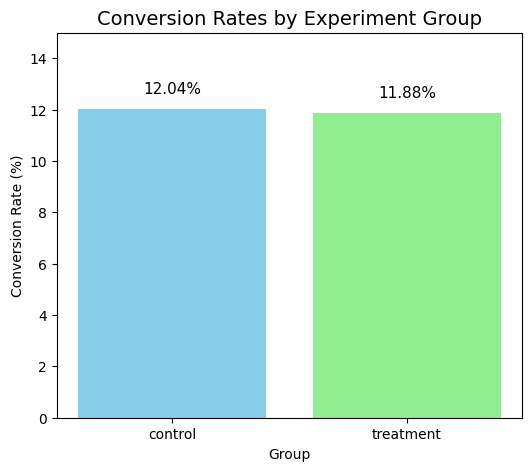

In [34]:
import matplotlib.pyplot as plt

conversion_rates=df_clean.groupby('group')['converted'].mean()

groups= conversion_rates.index
rates=conversion_rates.values * 100  # convert to percentages

# Create bar chart
plt.figure(figsize=(6,5))
bars =plt.bar(groups, rates, color=['skyblue','lightgreen'])

for bar, rate in zip(bars, rates):
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height()+ 0.5,
             f"{rate:.2f}%",ha='center',va='bottom',fontsize=11)

plt.title("Conversion Rates by Experiment Group", fontsize=14)
plt.xlabel("Group")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0,15)

plt.show()


# Step 16: Analyze Conversion Rates by Country

##### Now we'll investigate whether conversion behavior differs across the three countries in countries.csv.

#### ->Merge df_clean with countries using user_id as the common key.
#### ->Store the result in a new DataFrame named df_country

### Task 16.1 Merge the datasets

In [35]:
countries_df=pd.read_csv("countries.csv")
df_country=pd.merge(df_clean,countries_df,on="user_id",how="inner")

### Task 16.2 Validate the merged dataset

In [36]:
print("Rows:",df_country.shape[0])
print("Columns:",df_country.shape[1])
print("Missing values:",df_country.isnull().sum().sum())
print("Unique countries:",df_country['country'].nunique())
print("Countries:",df_country['country'].unique())

Rows: 290584
Columns: 6
Missing values: 0
Unique countries: 3
Countries: <StringArray>
['US', 'CA', 'UK']
Length: 3, dtype: str


### Task 16.3 Calculate conversion rates by country

In [37]:
conversion_by_country=df_country.groupby('country')['converted'].mean()*100
print("Conversion rates by country (%):")
print(conversion_by_country)

Conversion rates by country (%):
country
CA    11.531830
UK    12.059449
US    11.954680
Name: converted, dtype: float64


### Task 16.4 Compare the experiment groups by country

In [38]:
conversion_by_group_country=df_country.groupby(['country','group'])['converted'].mean()*100
print("Conversion rates by country and group (%):")
print(conversion_by_group_country)


Conversion rates by country and group (%):
country  group    
CA       control      11.878300
         treatment    11.190248
UK       control      12.002200
         treatment    12.117100
US       control      12.062999
         treatment    11.846560
Name: converted, dtype: float64


# Step 17: Visualize Conversion Rates by Country

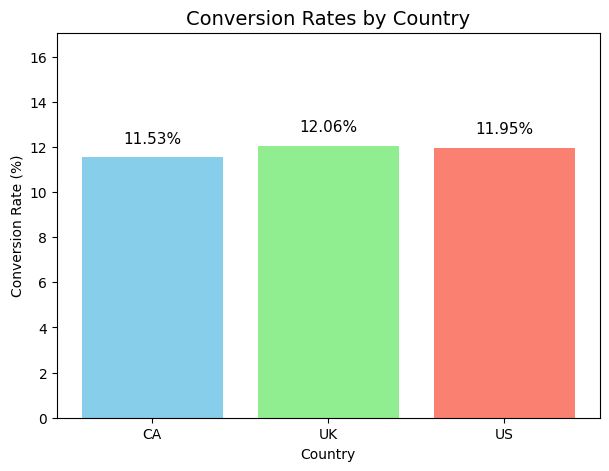

In [39]:
countries=conversion_by_country.index
rates=conversion_by_country.values

plt.figure(figsize=(7,5))
bars = plt.bar(countries,rates,color=['skyblue','lightgreen','salmon'])

for bar, rate in zip(bars, rates):
    plt.text(bar.get_x() + bar.get_width()/2,bar.get_height() + 0.5,
             f"{rate:.2f}%", ha='center', va='bottom', fontsize=11)

plt.title("Conversion Rates by Country",fontsize=14)
plt.xlabel("Country")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, max(rates) + 5)
plt.show()

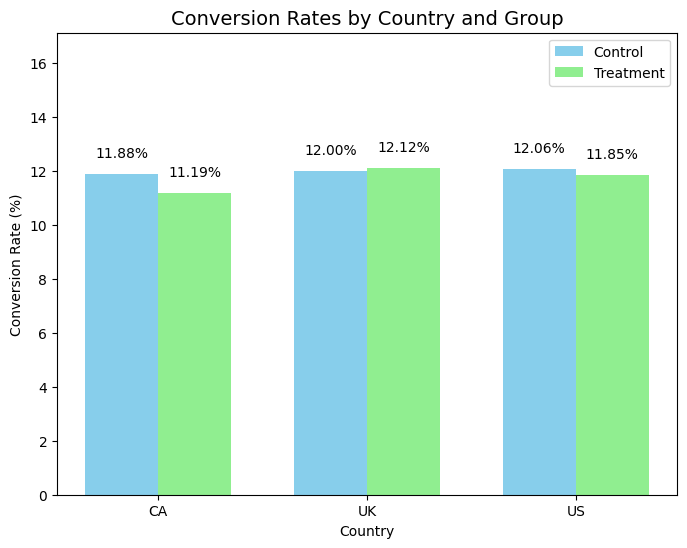

In [40]:
conversion_by_group_country = conversion_by_group_country.unstack()  # reshape for plotting

countries = conversion_by_group_country.index
control_rates = conversion_by_group_country['control'].values
treatment_rates = conversion_by_group_country['treatment'].values

x = range(len(countries))
bar_width = 0.35

plt.figure(figsize=(8,6))
bars1 = plt.bar([i - bar_width/2 for i in x], control_rates, width=bar_width, label='Control', color='skyblue')
bars2 = plt.bar([i + bar_width/2 for i in x], treatment_rates, width=bar_width, label='Treatment', color='lightgreen')

# Add labels above bars
for bars in [bars1, bars2]:
    for bar in bars:
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{bar.get_height():.2f}%", ha='center', va='bottom', fontsize=10)

plt.title("Conversion Rates by Country and Group", fontsize=14)
plt.xlabel("Country")
plt.ylabel("Conversion Rate (%)")
plt.xticks(x, countries)
plt.legend()
plt.ylim(0, max(control_rates.max(), treatment_rates.max()) + 5)
plt.show()

# Step 18: Analyze Conversion Trends Over Time

##### Now we'll investigate whether conversion behavior changes over the experiment period.

### Task 18.1 Convert the timestamp

##### timestamp column is currently stored as a string, Convert it to a proper Pandas datetime type

In [41]:
df_clean['timestamp']=pd.to_datetime(df_clean['timestamp'])

### Task 18.2 Extract the date

##### Create a new column named date containing only the date portion of each timestamp

In [42]:
df_clean['date']=df_clean['timestamp'].dt.date

### Task 18.3 Calculate daily conversion rates

In [43]:
daily_stats=df_clean.groupby('date').agg(users=('user_id','size'),conversions=('converted','sum'),conversion_rate=('converted','mean')).reset_index()

# Convert to percentage
daily_stats['conversion_rate']=daily_stats['conversion_rate']*100

print(daily_stats.head())


         date  users  conversions  conversion_rate
0  2017-01-02   5712          701        12.272409
1  2017-01-03  13208         1503        11.379467
2  2017-01-04  13119         1565        11.929263
3  2017-01-05  12932         1540        11.908444
4  2017-01-06  13353         1595        11.944881


### Task 18.4 Visualize daily conversion rates

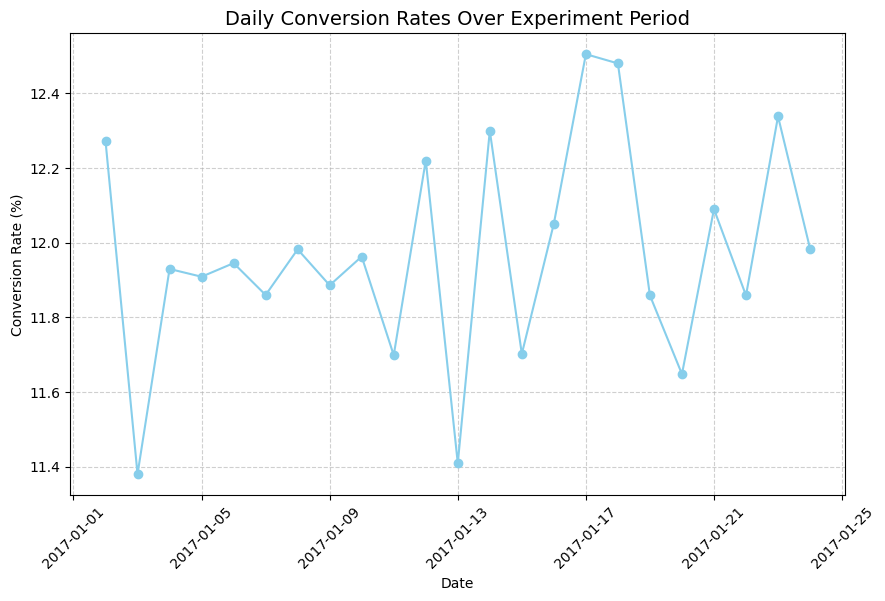

In [44]:
plt.figure(figsize=(10,6))
plt.plot(daily_stats['date'],daily_stats['conversion_rate'],marker='o',linestyle='-',color='skyblue')

plt.title("Daily Conversion Rates Over Experiment Period",fontsize=14)
plt.xlabel("Date")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, linestyle='--',alpha=0.6)

plt.show()

# Step 19: Compare Daily Conversion Rates by Experiment Group

##### Now we'll investigate whether the difference between the old and new pages changes over time.

### Task 19.1 Calculate daily conversion rates by group

In [45]:
# Daily conversion rates by group
daily_group_stats=df_clean.groupby(['date','group']).agg(conversions=('converted','sum'),users=('user_id','size'),
conversion_rate=('converted','mean')).reset_index()

# Convert to percentage
daily_group_stats['conversion_rate']=daily_group_stats['conversion_rate']*100
print(daily_group_stats.head(6))

         date      group  conversions  users  conversion_rate
0  2017-01-02    control          359   2859        12.556838
1  2017-01-02  treatment          342   2853        11.987382
2  2017-01-03    control          750   6590        11.380880
3  2017-01-03  treatment          753   6618        11.378060
4  2017-01-04    control          802   6578        12.192156
5  2017-01-04  treatment          763   6541        11.664883


### Task 19.2 Reshape the results

In [46]:
# Pivot so each date has control and treatment columns
daily_group_pivot=daily_group_stats.pivot(index='date',columns='group',values='conversion_rate')
print(daily_group_pivot.head())


group         control  treatment
date                            
2017-01-02  12.556838  11.987382
2017-01-03  11.380880  11.378060
2017-01-04  12.192156  11.664883
2017-01-05  12.323012  11.498847
2017-01-06  11.534968  12.346228


#### Task 19.3 Create a comparison line chart

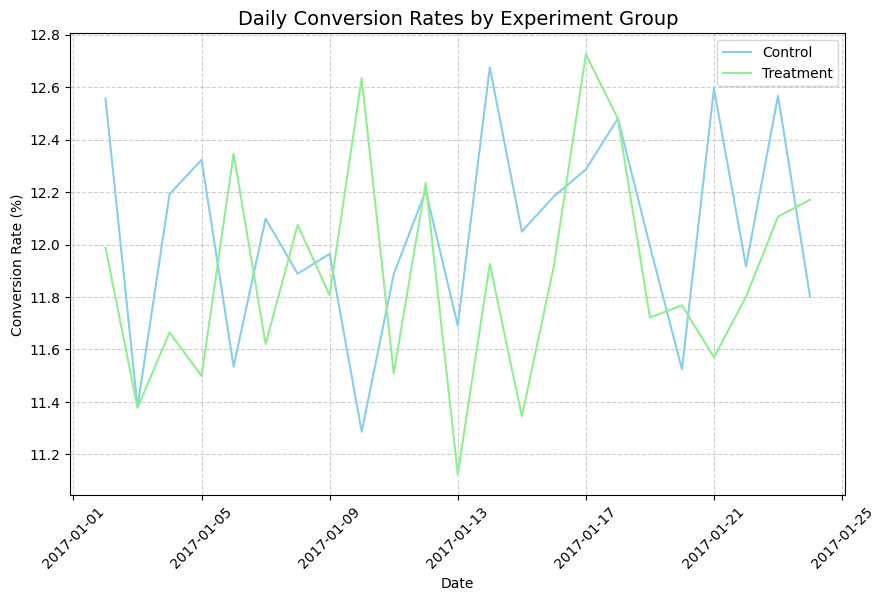

In [47]:
plt.figure(figsize=(10,6))
plt.plot(daily_group_pivot.index,daily_group_pivot['control'],label='Control',color='skyblue')
plt.plot(daily_group_pivot.index,daily_group_pivot['treatment'],label='Treatment',color='lightgreen')

plt.title("Daily Conversion Rates by Experiment Group",fontsize=14)
plt.xlabel("Date")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle='--',alpha=0.6)

plt.show()

# Step 20: Final Statistical Conclusions and Business Recommendations

### 20.1 Summarize the experiment results

In [48]:
# Conversion rates
control_rate = conversion_rates['control']
treatment_rate = conversion_rates['treatment']

# Absolute difference in percentage points
absolute_diff = (treatment_rate - control_rate) * 100

# Relative conversion lift
relative_lift = ((treatment_rate - control_rate) / control_rate) * 100

# Create a results summary
experiment_summary = pd.DataFrame({
    'Metric': [
        'Control conversion rate',
        'Treatment conversion rate',
        'Absolute conversion difference (percentage points)',
        'Relative conversion lift (%)',
        'Z-statistic',
        'P-value',
        '95% CI lower bound (percentage points)',
        '95% CI upper bound (percentage points)'
    ],
    'Result': [
        control_rate * 100,
        treatment_rate * 100,
        absolute_diff,
        relative_lift,
        z_stat,
        p_value,
        ci_lower * 100,
        ci_upper * 100
    ]
})

print("A/B Testing Experiment Summary")
print(experiment_summary.round(4).to_string(index=False))

A/B Testing Experiment Summary
                                            Metric  Result
                           Control conversion rate 12.0386
                         Treatment conversion rate 11.8808
Absolute conversion difference (percentage points) -0.1578
                      Relative conversion lift (%) -1.3110
                                       Z-statistic -1.3109
                                           P-value  0.9051
            95% CI lower bound (percentage points) -0.3938
            95% CI upper bound (percentage points)  0.0781


### 20.2 Statistical conclusion

In [49]:
alpha = 0.05

print("Statistical Conclusion:")

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is statistically significant evidence that the new page improves conversion.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient statistical evidence that the new page improves conversion.")

print(f"\nP-value: {p_value:.4f}")
print(f"Significance level: {alpha}")
print(f"95% confidence interval: ({ci_lower * 100:.4f}, {ci_upper * 100:.4f}) percentage points")

Statistical Conclusion:
Fail to reject the null hypothesis.
There is insufficient statistical evidence that the new page improves conversion.

P-value: 0.9051
Significance level: 0.05
95% confidence interval: (-0.3938, 0.0781) percentage points


### 20.3 Business recommendation

In [50]:
print("Business Recommendation:")

if p_value<alpha and treatment_rate > control_rate:
    print(
        "The new landing page has a higher observed conversion rate, "
        "and the result is statistically significant. Consider rolling it out "
        "gradually while monitoring conversion and other business metrics."
    )
else:
    print(
        "The experiment does not provide sufficient statistical evidence "
        "that the new landing page improves conversions. Retain the old page "
        "for now and consider testing a revised design in a future experiment."
    )

Business Recommendation:
The experiment does not provide sufficient statistical evidence that the new landing page improves conversions. Retain the old page for now and consider testing a revised design in a future experiment.


### 20.4 Experiment limitations

In [51]:
limitations = [
    "The original dataset contained repeated user IDs and records with mismatched experiment group and landing-page assignments. Data cleaning was necessary, and the cleaning rules may affect the analyzed sample.",
    "Daily conversion rates fluctuate. Daily patterns alone do not establish that one page performs better; the overall experiment and statistical test are more appropriate for evaluating the difference.",
    "The analysis focuses on conversion. Other business outcomes, such as revenue per visitor, order value, and user experience, were not evaluated."
]

print("Experiment Limitations:")
for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")

Experiment Limitations:
1. The original dataset contained repeated user IDs and records with mismatched experiment group and landing-page assignments. Data cleaning was necessary, and the cleaning rules may affect the analyzed sample.
2. Daily conversion rates fluctuate. Daily patterns alone do not establish that one page performs better; the overall experiment and statistical test are more appropriate for evaluating the difference.
3. The analysis focuses on conversion. Other business outcomes, such as revenue per visitor, order value, and user experience, were not evaluated.


In [52]:
# Export cleaned dataset to CSV
df_clean.to_csv("ab_testing_cleaned.csv",index=False)
